# 06 — Thorlabs AL1225: full propagation pipeline

The main example is now the **AL1225 catalog lens**. The figures below are newly computed fields for its **scaled prescription**, using the complete **spectral** $R_fQ^{-1}TQR_{z_0}$ pipeline at both faces. The manufactured lens has R/λ = 8,012.82 at 780 nm; its full-size propagation remains pending.

The old sphere, arbitrary freeforms and their stored plots have moved to the [synthetic-study archive](archive/06_synthetic_reference_validation.ipynb).

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import vecdiff_general as optics
from vecdiff_general.propagation.references.al1225 import (
    load_al1225_study,
    show_al1225_study,
)

plt.rcParams.update({"image.cmap": "hot", "figure.dpi": 95, "font.size": 9})
root = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "general/pyproject.toml").exists()
)

## Thorlabs AL1225 — physical lens prescription

Our practical lens benchmark is the **uncoated AL1225**: N-BK7, diameter **12.5 mm**, center thickness **4 mm**, nominal EFL **25 mm**, NA **0.23**, design wavelength **780 nm**. The aspheric face faces the incoming collimated beam; the exit is planar. The physical rim gives **R/λ = 8,012.82**. R denotes the body radius, not the 12.78 mm vertex radius of curvature.

The prescription uses the [Thorlabs V21 catalogue, printed p. 744](https://www.thorlabs.com/images/Catalog/V21/V21_3_Optics.pdf), including all terms A₄ through A₁₆. Its clear diameters are 11.25 mm at the asphere and 10.42 mm at the plane (rounded to 11.3/10.4 mm in the newer product table). Clear optical zones are not opaque stops. [SCHOTT N-BK7 dispersion](https://www.schott.com/en-gb/products/optical-glass/-/media/Project/OnEx/Products/O/optical-glass/Downloads/schott-optical-glass-collection-datasheets-english-may2019.pdf) gives n = 1.51118331 at 780 nm. We model the nominal lossless prescription with a sharp circular rim, without manufacturing errors or bevels.

**Status: geometry implemented; full-size field, runtime and independent complex-field accuracy pending.** The optical system retains finite edges. The current forward pipeline rejects these; its continued-face approximation must be declared explicitly before comparison with closed-body BEM. No field result or timing from a smaller scaled model is a measurement for the manufactured lens. The previous synthetic geometries and results are preserved in the [archive](archive/06_synthetic_reference_validation.ipynb).


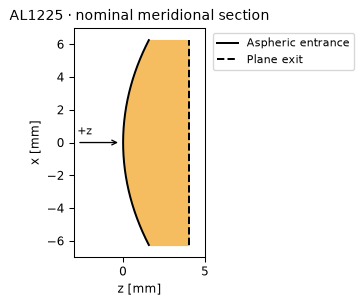

λ = 780 nm; n = 1.51118331
Body R/λ = 8,012.82; entrance clear radius/λ = 7,211.54
Full-size field / runtime / independent complex-field error: not yet computed.


In [2]:
import numpy as np

al1225_wavelength = 780e-9
al1225 = optics.thorlabs_al1225(wavelength0=al1225_wavelength)
al1225_front, al1225_back = al1225.interfaces
al1225_radius = al1225.apertures[0]
al1225_body = optics.VolumeBetweenSurfaces(
    al1225_front.surface, al1225_back.surface, al1225_radius
)

x_profile = np.linspace(-al1225_radius, al1225_radius, 501)
xy_profile = np.column_stack((x_profile, np.zeros_like(x_profile)))
z_front = al1225_front.surface.points(xy_profile)[:, 2]
z_back = al1225_back.surface.points(xy_profile)[:, 2]
fig, ax = plt.subplots(figsize=(6.4, 3.1), constrained_layout=True)
ax.fill_betweenx(x_profile * 1e3, z_front * 1e3, z_back * 1e3, color="#f6bd60")
ax.plot(z_front * 1e3, x_profile * 1e3, "k", label="Aspheric entrance")
ax.plot(z_back * 1e3, x_profile * 1e3, "k--", label="Plane exit")
ax.annotate("", xy=(-0.15, 0), xytext=(-2.8, 0), arrowprops={"arrowstyle": "->"})
ax.text(-2.8, 0.5, "+z", fontsize=8)
ax.set(
    xlabel="z [mm]",
    ylabel="x [mm]",
    title="AL1225 · nominal meridional section",
    xlim=(-3, 5),
    ylim=(-7, 7),
    aspect="equal",
)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()
print(f"λ = {al1225_wavelength * 1e9:.0f} nm; n = {al1225_front.plus.material.n:.8f}")
print(
    f"Body R/λ = {al1225_radius / al1225_wavelength:,.2f}; "
    f"entrance clear radius/λ = {5.625e-3 / al1225_wavelength:,.2f}"
)
print("Full-size field / runtime / independent complex-field error: not yet computed.")

## Calculated fields: R/λ = 3, 10, 30, 100

Every geometric length scales together; wavelength remains **780 nm**, with **n = 1.51118331** in the glass and n = 1 in air. R is the physical rim radius. Illumination is a collimated, x-polarized plane wave, Ex = 1 V/m. These scaled bodies are not the manufactured 12.5 mm lens.

The pipeline uses exact catalog faces inside the rim and a continuous-slope radial continuation outside it (tail length 0.05R). This changes the exterior material distribution and omits rim scattering and returning reflections. The finite catalog system itself is not passed off as an open system.

Each image has an intensity colorbar and uses `hot`. **Coverage is `complete`: every meridional grid point is evaluated in its graph-defined material region, including the curved interface bands.** No field values are interpolated. Exact boundary samples use the plus-side limit. Points outside the nominal rim still belong to the continued-face model, not a finite-rim scattering solution. The meridional observation spacing is at most 0.5λ in both coordinates; this replaces the previous fixed-size observation grid. Focal views span **±8λ**, at the pipeline's downstream on-axis maximum when no BEM reference is available. Plot sampling is not an accuracy bound.

The FFT chart spans max(12λ, 4R), with spacing resolving the configured spectral band in both materials. Fresnel settings remain 18 angular nodes per coordinate, cutoff 10⁻⁷, angular limit 0.65 and retained sine 0.95; two threads, one worker. Each size is a fresh solve. BEM retains h/λ = 0.20 and the 5,000-unknown limit.

The notebook displays saved fields and measured solver times from these runs. To recompute them, run `validation/al1225_benchmark.py` from the repository root; reloading this notebook does not repeat the solves or measure a new runtime.

The operational API is `PropagationPipeline(system, transmission="spectral", coverage="complete")`, followed by `propagate(incident_field, y=0, ..., side="plus")`. Select `coverage="reduced"` to disable evaluation in curved interface bands. Both modes reuse the same interface calculations. Complete coverage extends the existing forward modal field; near-interface complex-field accuracy and evanescent contributions remain unvalidated.

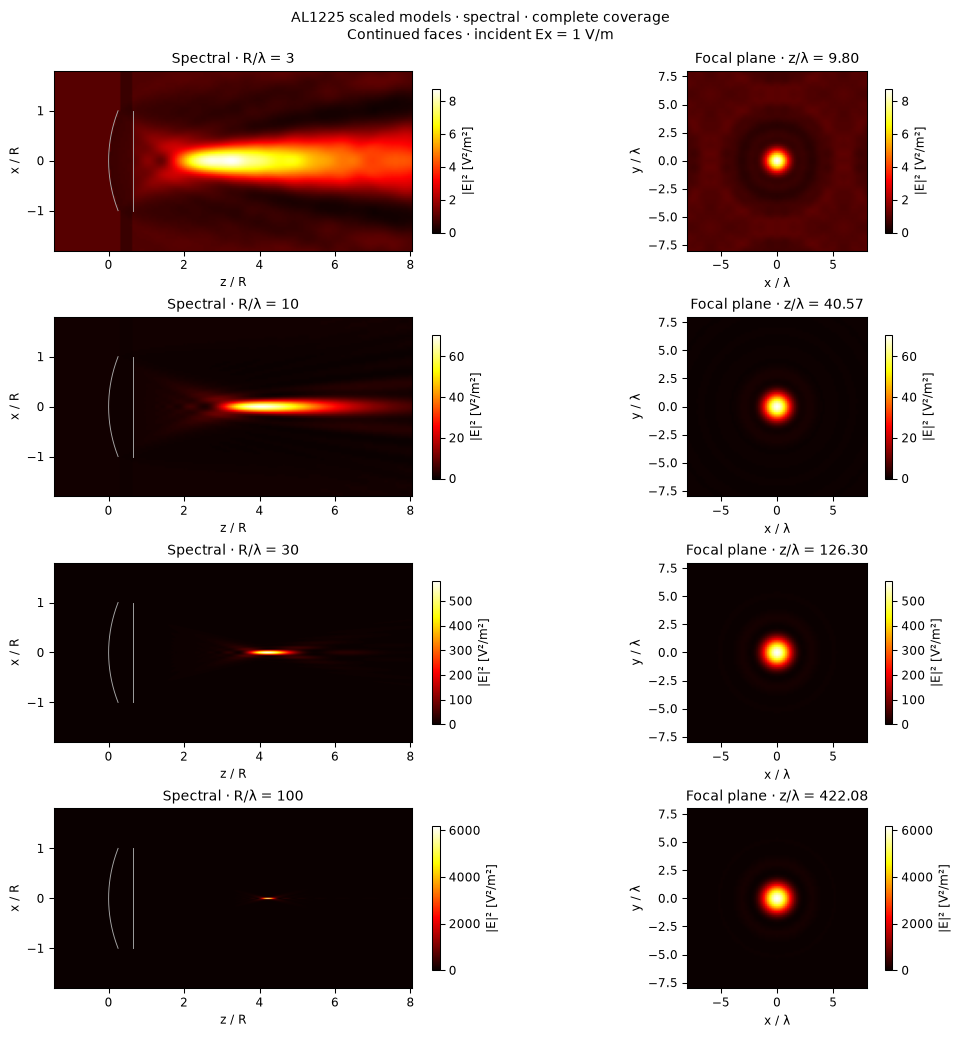

R/λ,FFT grid,Full spectral focal run [s],All requested fields [s],BEM,Complex E difference vs BEM
3,128²,1.203,1.347,Not computed (dense limit),Unavailable
10,128²,1.109,1.552,Not computed (dense limit),Unavailable
30,384²,11.927,16.139,Not computed (dense limit),Unavailable
100,1280²,396.853,543.243,Not computed (dense limit),Unavailable


In [3]:
record = root / "validation/reference_data/al1225_size_study.npz"
al1225_results = load_al1225_study(record)
show_al1225_study(al1225_results)

The **full spectral focal time** includes preparation, both interface applications and reconstruction of E/H at all 6,561 focal points. **All requested fields** additionally includes the axial scan, complete meridian and interface reconstruction. Imports, plotting and the BEM capacity check are excluded. These are wall times for the executed scaled models, not estimates for the full-size lens.

**Independent complex-field accuracy is unavailable wherever BEM was not computed.** The catalog focal length, sharpness of the image and agreement between pipeline runs do not establish that accuracy. Mie does not apply to this nonspherical lens. Full-size runtime and accuracy remain unmeasured.